**Finding High-Need Countries through Data Mining**

# **1. Data Cleaning & Processing**



## Import Libraries

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
from matplotlib.ticker import PercentFormatter

## Load Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


df = pd.read_csv('/content/drive/MyDrive/Country-data.csv')

#Check number of rows and columns in the dataset
print("The dataset has %d rows and %d columns." % df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
The dataset has 167 rows and 10 columns.


## Checking the data

In [ ]:
df.head(20)

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.440,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.490,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.100,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.400,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.440,76.8,2.13,12200
5,Argentina,14.5,18.9,8.10,16.0,18700,20.900,75.8,2.37,10300
6,Armenia,18.1,20.8,4.40,45.3,6700,7.770,73.3,1.69,3220
7,Australia,4.8,19.8,8.73,20.9,41400,1.160,82.0,1.93,51900
8,Austria,4.3,51.3,11.00,47.8,43200,0.873,80.5,1.44,46900
9,Azerbaijan,39.2,54.3,5.88,20.7,16000,13.800,69.1,1.92,5840


## Describing the dataset

In [ ]:
df.describe()

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000
mean,38.270060,41.108976,6.815689,46.890215,17144.688623,7.781832,70.555689,2.947964,12964.155689
std,40.328931,27.412010,2.746837,24.209589,19278.067698,10.570704,8.893172,1.513848,18328.704809
min,2.600000,0.109000,1.810000,0.065900,609.000000,-4.210000,32.100000,1.150000,231.000000
25%,8.250000,23.800000,4.920000,30.200000,3355.000000,1.810000,65.300000,1.795000,1330.000000
50%,19.300000,35.000000,6.320000,43.300000,9960.000000,5.390000,73.100000,2.410000,4660.000000
75%,62.100000,51.350000,8.600000,58.750000,22800.000000,10.750000,76.800000,3.880000,14050.000000
max,208.000000,200.000000,17.900000,174.000000,125000.000000,104.000000,82.800000,7.490000,105000.000000


## Finding missing values

In [ ]:
missing_values = df[pd.isnull(df).any(axis=1)]
missing_values

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp


## Finding duplicate rows

In [ ]:
duplicate_rows = df[df.duplicated()]
duplicate_rows

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp


## Feature Information

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    object 
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), object(1)
memory usage: 13.2+ KB


## Data Transformation

In [ ]:
# Keep country only as an identifier
country_names = df['country']

# Use only numeric features for modeling
df_numeric = df.drop(columns=['country'])

In [ ]:
standardized_df = df_numeric.copy()

standardized_df['child_mort']=(df_numeric['child_mort']-df_numeric['child_mort'].mean())/(df_numeric['child_mort'].std())
standardized_df['exports']=(df_numeric['exports']-df_numeric['exports'].mean())/(df_numeric['exports'].std())
standardized_df['health']=(df_numeric['health']-df_numeric['health'].mean())/(df_numeric['health'].std())
standardized_df['imports']=(df_numeric['imports']-df_numeric['imports'].mean())/(df_numeric['imports'].std())
standardized_df['income']=(df_numeric['income']-df_numeric['income'].mean())/(df_numeric['income'].std())
standardized_df['inflation']=(df_numeric['inflation']-df_numeric['inflation'].mean())/(df_numeric['inflation'].std())
standardized_df['life_expec']=(df_numeric['life_expec']-df_numeric['life_expec'].mean())/(df_numeric['life_expec'].std())
standardized_df['total_fer']=(df_numeric['total_fer']-df_numeric['total_fer'].mean())/(df_numeric['total_fer'].std())
standardized_df['gdpp']=(df_numeric['gdpp']-df_numeric['gdpp'].mean())/(df_numeric['gdpp'].std())

In [ ]:
standardized_df.head(20)

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,1.287660,-1.134867,0.278251,-0.082208,-0.805822,0.156864,-1.614237,1.897176,-0.677143
1,-0.537333,-0.478220,-0.096725,0.070624,-0.374243,-0.311411,0.645924,-0.857394,-0.484167
2,-0.272015,-0.098824,-0.963176,-0.639838,-0.220182,0.786908,0.668413,-0.038289,-0.463980
3,2.001787,0.773056,-1.443729,-0.164820,-0.583289,1.382894,-1.175698,2.121770,-0.514720
4,-0.693548,0.160186,-0.286034,0.496076,0.101427,-0.599944,0.702147,-0.540321,-0.041692
5,-0.589405,-0.810191,0.467560,-1.275950,0.080678,1.240993,0.589701,-0.381785,-0.145354
6,-0.500139,-0.740879,-0.879444,-0.065685,-0.541791,-0.001119,0.308586,-0.830971,-0.531634
7,-0.829927,-0.777359,0.696915,-1.073550,1.258182,-0.626432,1.286865,-0.672435,2.124310
8,-0.842325,0.371772,1.523320,0.037580,1.351552,-0.653583,1.118196,-0.996114,1.851513
9,0.023059,0.481213,-0.340642,-1.081812,-0.059378,0.569325,-0.163686,-0.679041,-0.388688


# **2. Exploratory Data Analysis**

## **Univariate Analysis**

### Histogram

In [ ]:
numerical_columns = [
      'child_mort',
      'exports',
      'health',
      'imports',
      'income',
      'inflation',
      'life_expec',
      'total_fer',
      'gdpp'
]

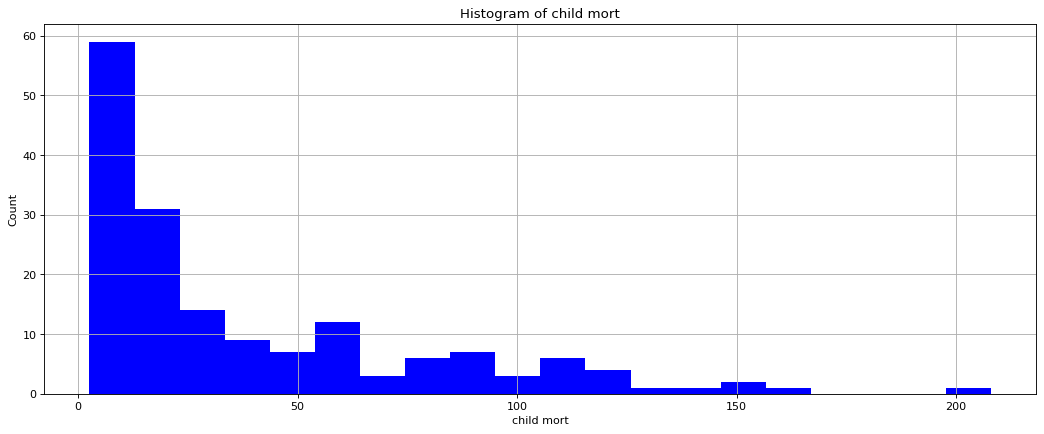

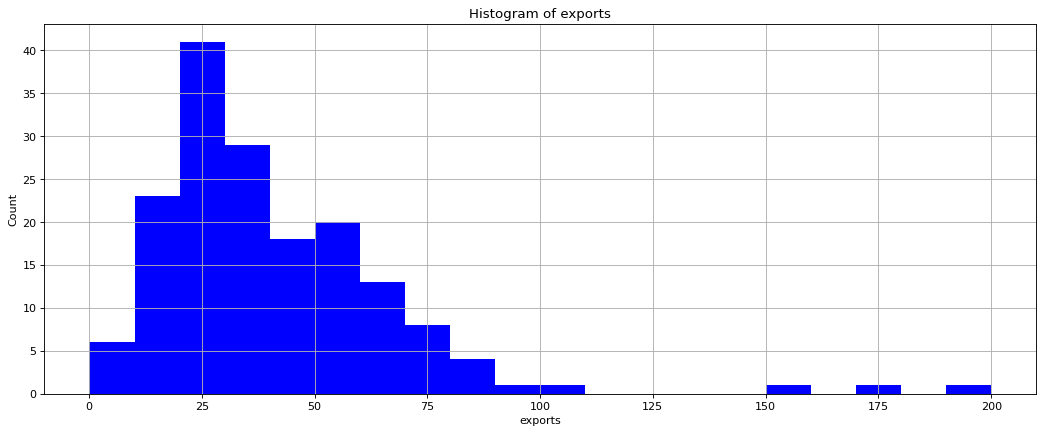

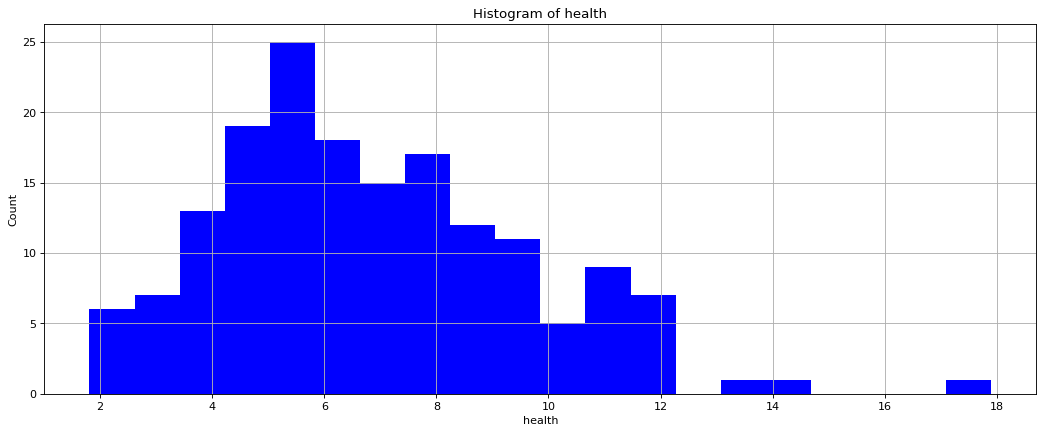

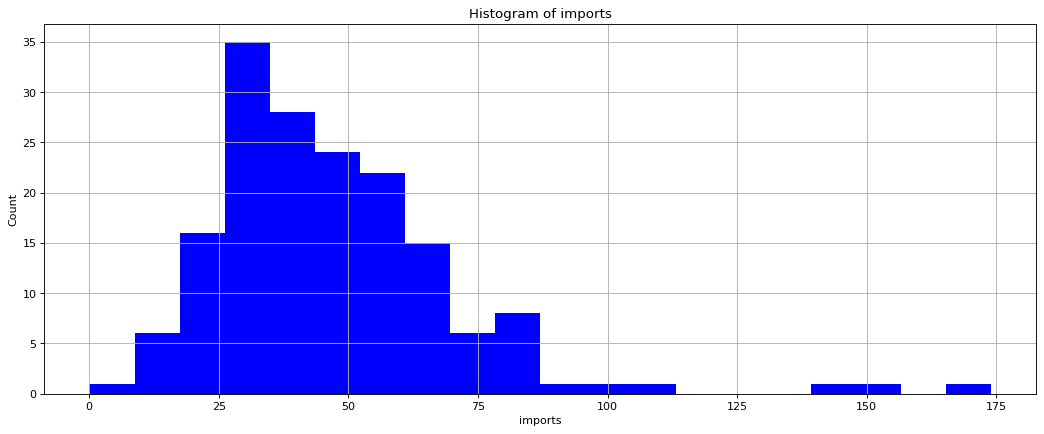

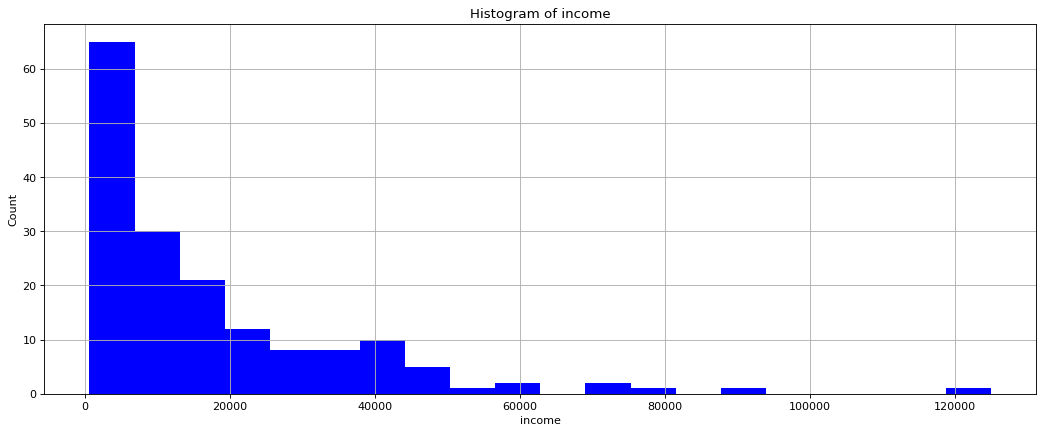

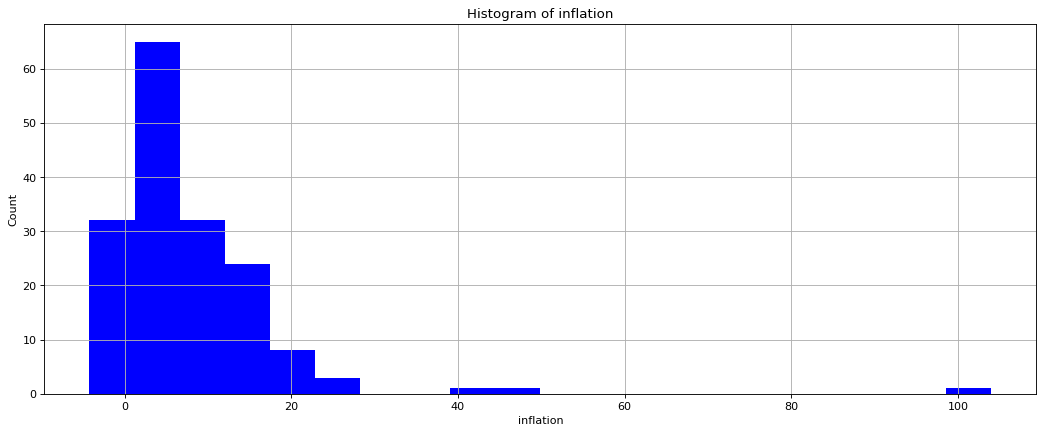

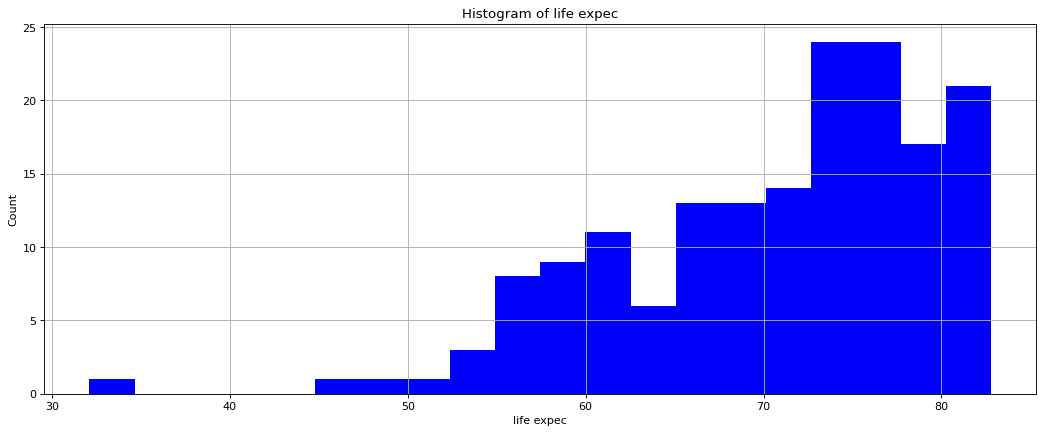

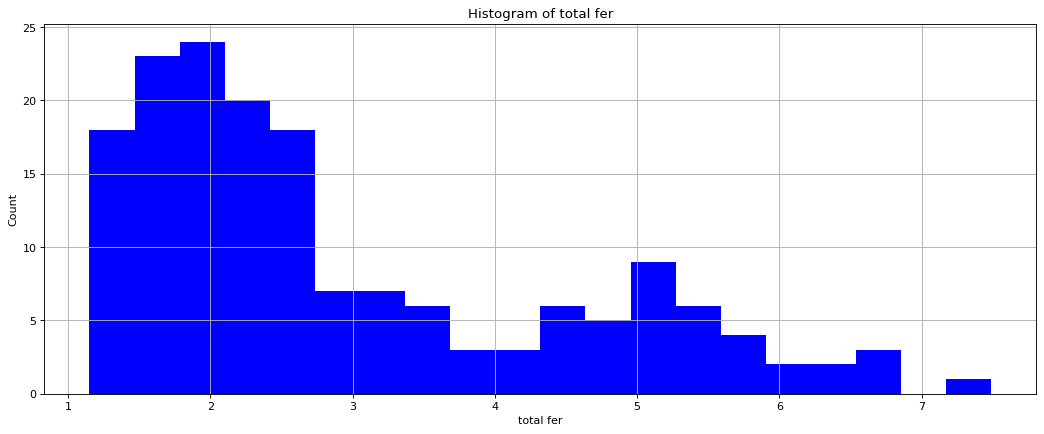

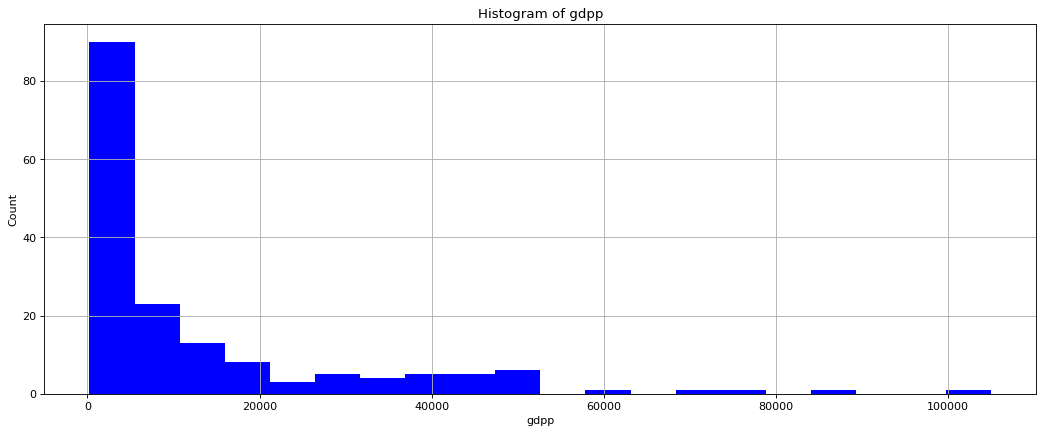

In [ ]:
# the histogram of the data
for col in numerical_columns:
    plt.figure(figsize=(16, 6), dpi=80)
    plt.hist(df_numeric[col], bins=20, facecolor='b')
    plt.xlabel(col.replace('_', ' '))
    plt.ylabel('Count')
    plt.title(f'Histogram of {col.replace("_", " ")}')
    plt.grid(True)
    plt.show()

### Box Plot

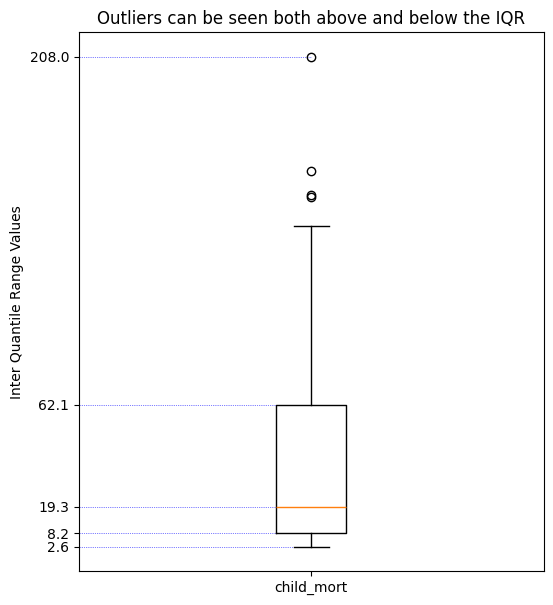

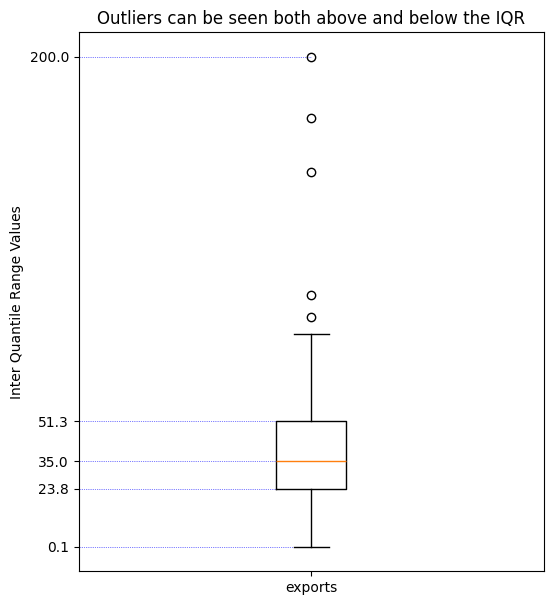

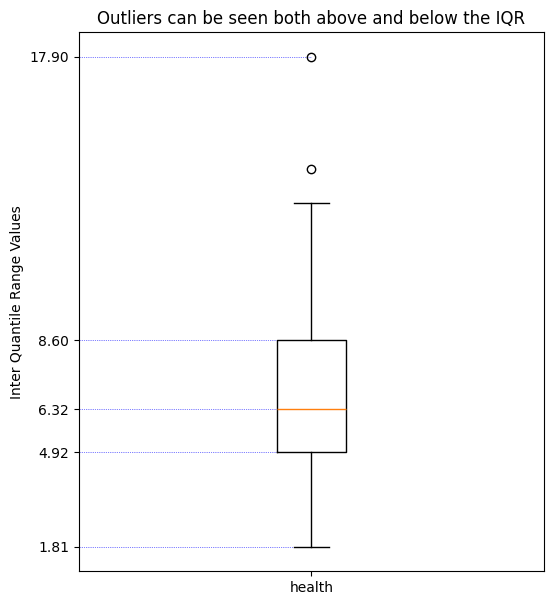

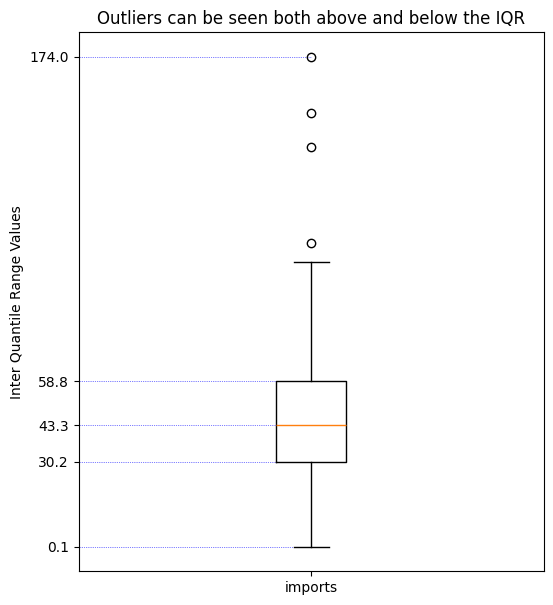

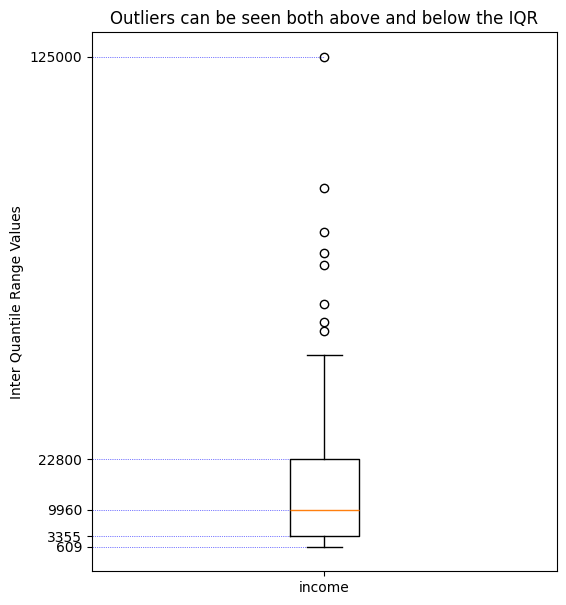

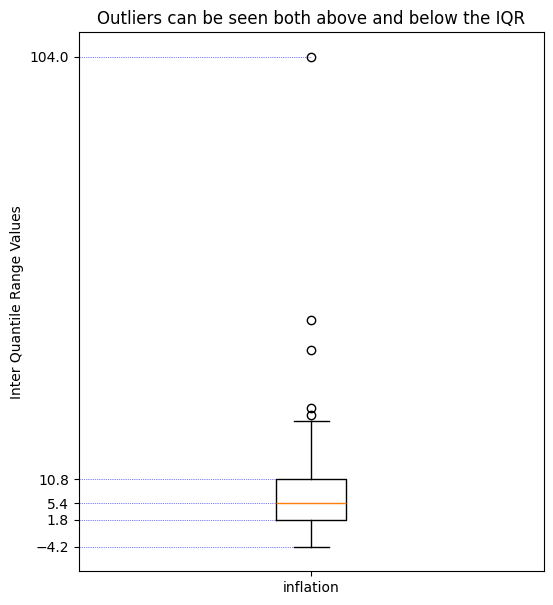

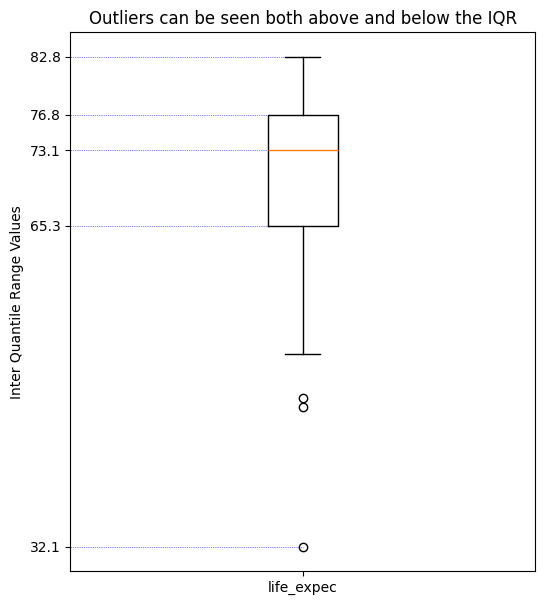

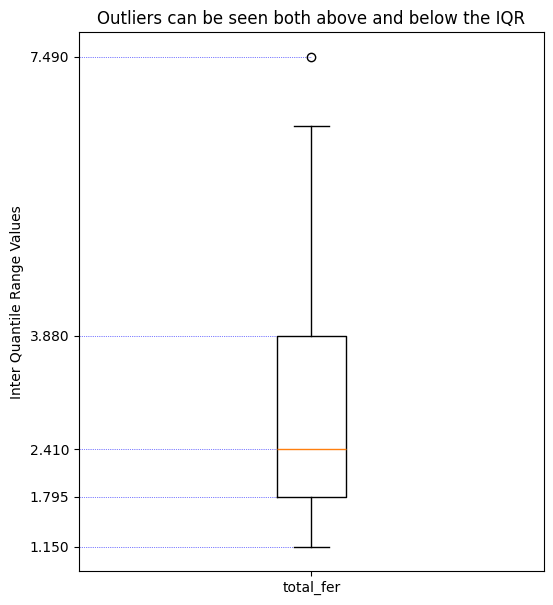

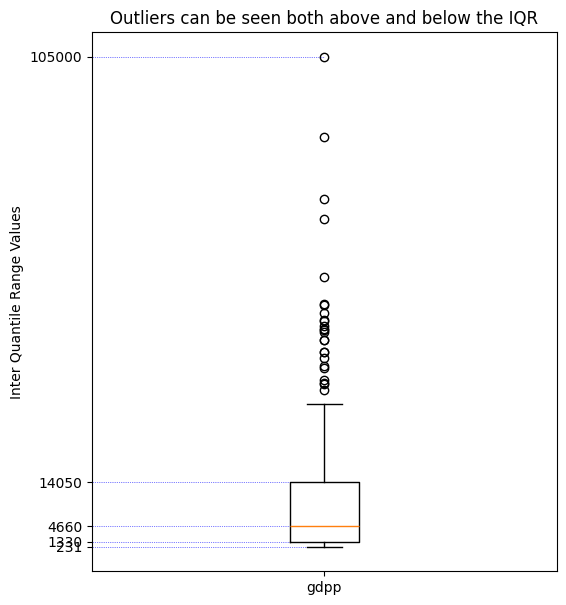

In [ ]:
for col in numerical_columns:
    fig = plt.figure(1, figsize=(6, 7))
    ax = fig.add_subplot(111)
    ax.set_title('Outliers can be seen both above and below the IQR')
    ax.boxplot(df_numeric[col], vert=True, manage_ticks=True)
    ax.set_ylabel('Inter Quantile Range Values')
    # ax.set_yticklabels(['Min','Q1','Median', 'Q3','Max'])
    ax.set_xticklabels([col])

    quantiles = np.quantile(df_numeric[col], np.array([0.00, 0.25, 0.50, 0.75, 1.00]))

    ax.hlines(quantiles, [0] * quantiles.size, [1] * quantiles.size,
              color='b', ls=':', lw=0.5, zorder=0)
    ax.set_xlim(0.5, 1.5)
    ax.set_yticks(quantiles)
    plt.show()

The box plots show that many numeric columns have outliers, mostly very high values (especially *child_mort*, *income*, *inflation*, and *gdpp*; **life_expec** ,**health** are showing some lower outliers). We did not delete or remove these outliers, but but their influence on clustering was reduced by **Z-score standardization** so no single extreme-valued feature dominated distance calculations.

## **Bivariate Analysis**

### Scatterplots

### **Child Mortality vs. GDP per Capita**

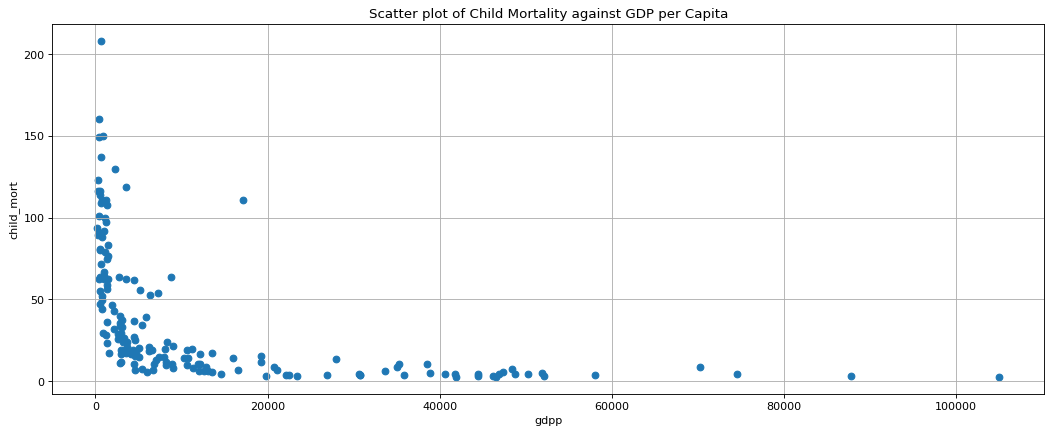

In [ ]:
figure(figsize=(16, 6), dpi=80)

plt.scatter(df_numeric['gdpp'],df_numeric['child_mort'])

plt.xlabel('gdpp')
plt.ylabel('child_mort')


plt.title('Scatter plot of Child Mortality against GDP per Capita')

plt.grid(True)
plt.show()

### **Life Expectancy vs. Income**

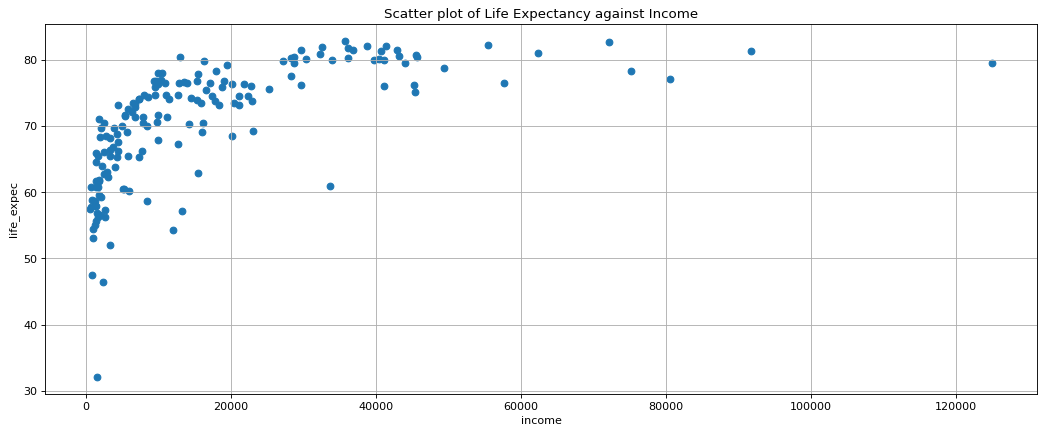

In [ ]:
figure(figsize=(16, 6), dpi=80)

plt.scatter(df_numeric['income'],df_numeric['life_expec'])

plt.xlabel('income')
plt.ylabel('life_expec')


plt.title('Scatter plot of Life Expectancy against Income')

plt.grid(True)
plt.show()

### **Total Fertility vs. Health Spending**

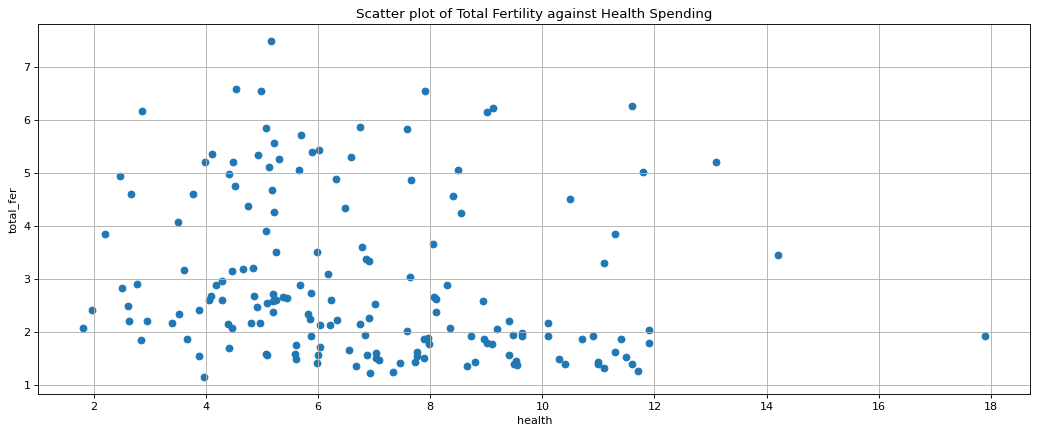

In [ ]:
figure(figsize=(16, 6), dpi=80)

plt.scatter(df_numeric['health'],df_numeric['total_fer'])

plt.xlabel('health')
plt.ylabel('total_fer')


plt.title('Scatter plot of Total Fertility against Health Spending')

plt.grid(True)
plt.show()

### **Inflation vs. GDP per Capita**

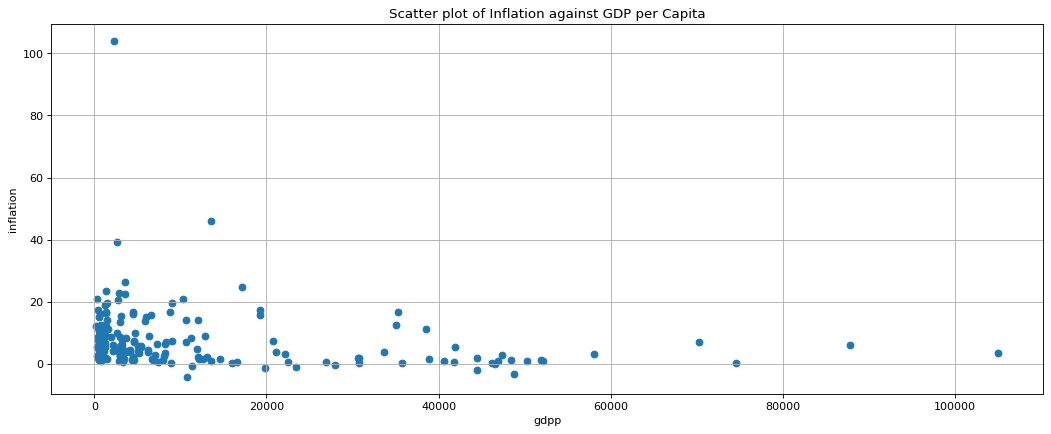

In [ ]:
figure(figsize=(16, 6), dpi=80)

plt.scatter(df_numeric['gdpp'],df_numeric['inflation'])

plt.xlabel('gdpp')
plt.ylabel('inflation')


plt.title('Scatter plot of Inflation against GDP per Capita')

plt.grid(True)
plt.show()

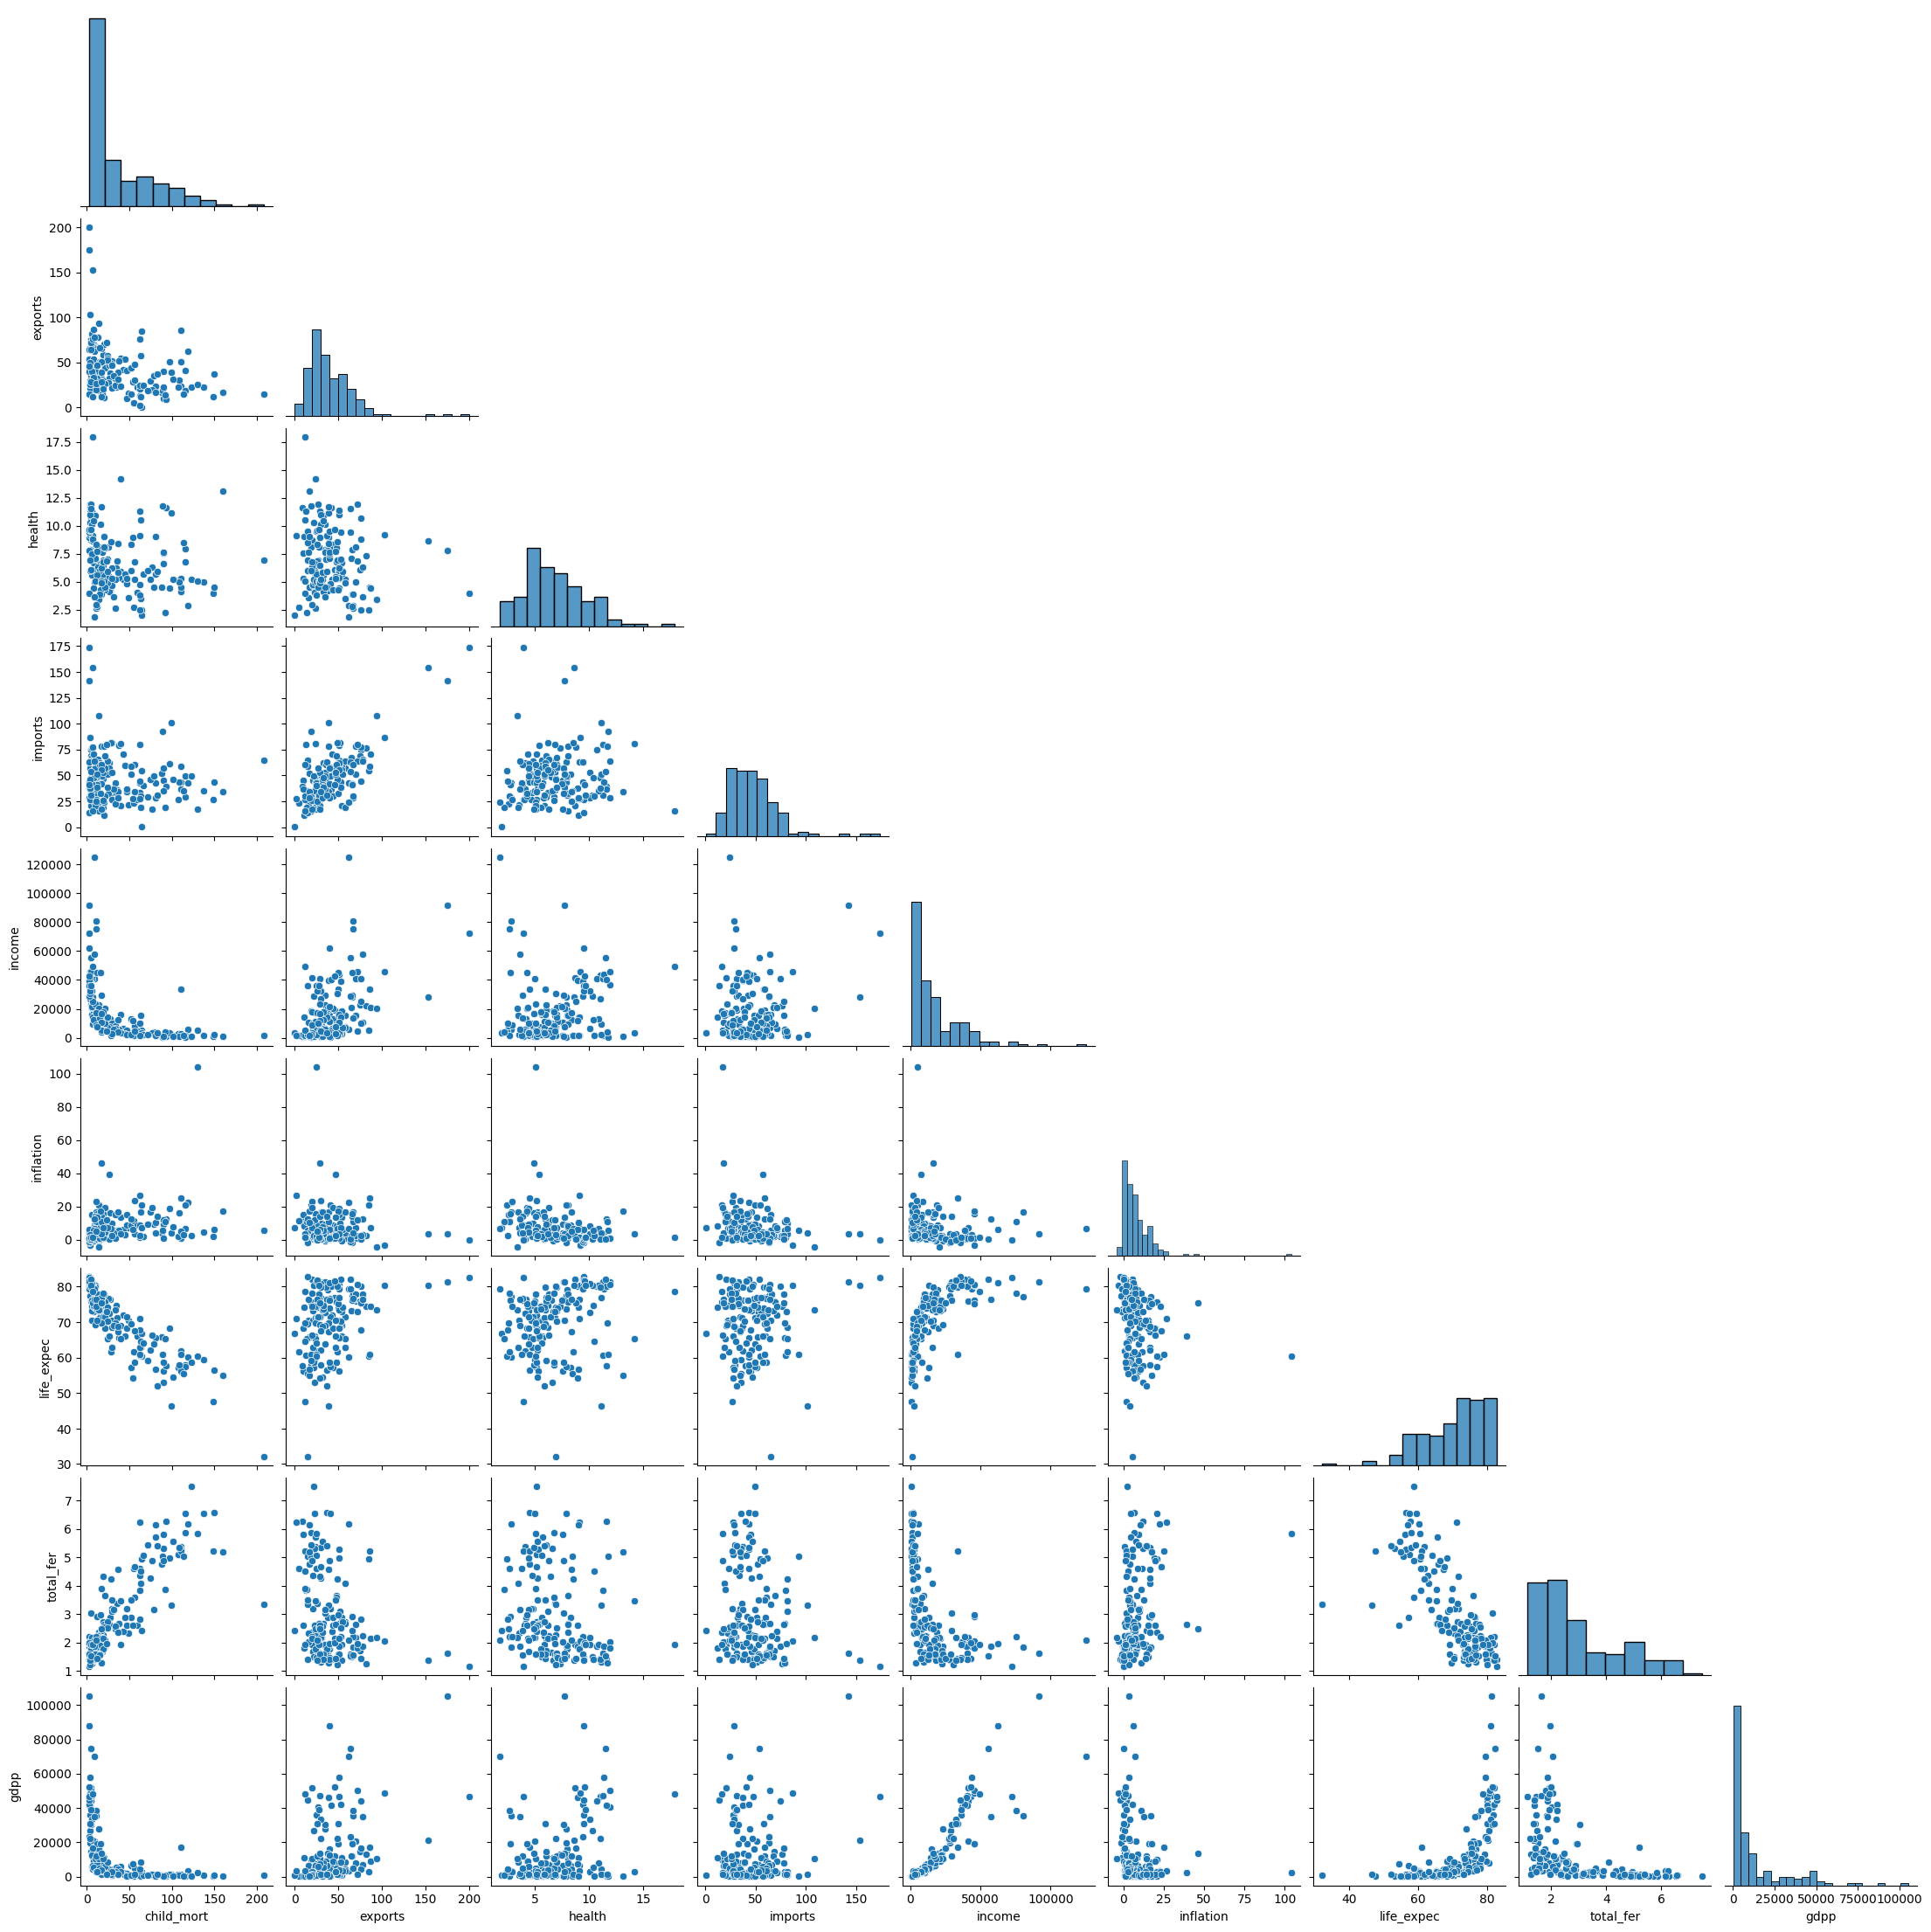

<Figure size 1500x1500 with 0 Axes>

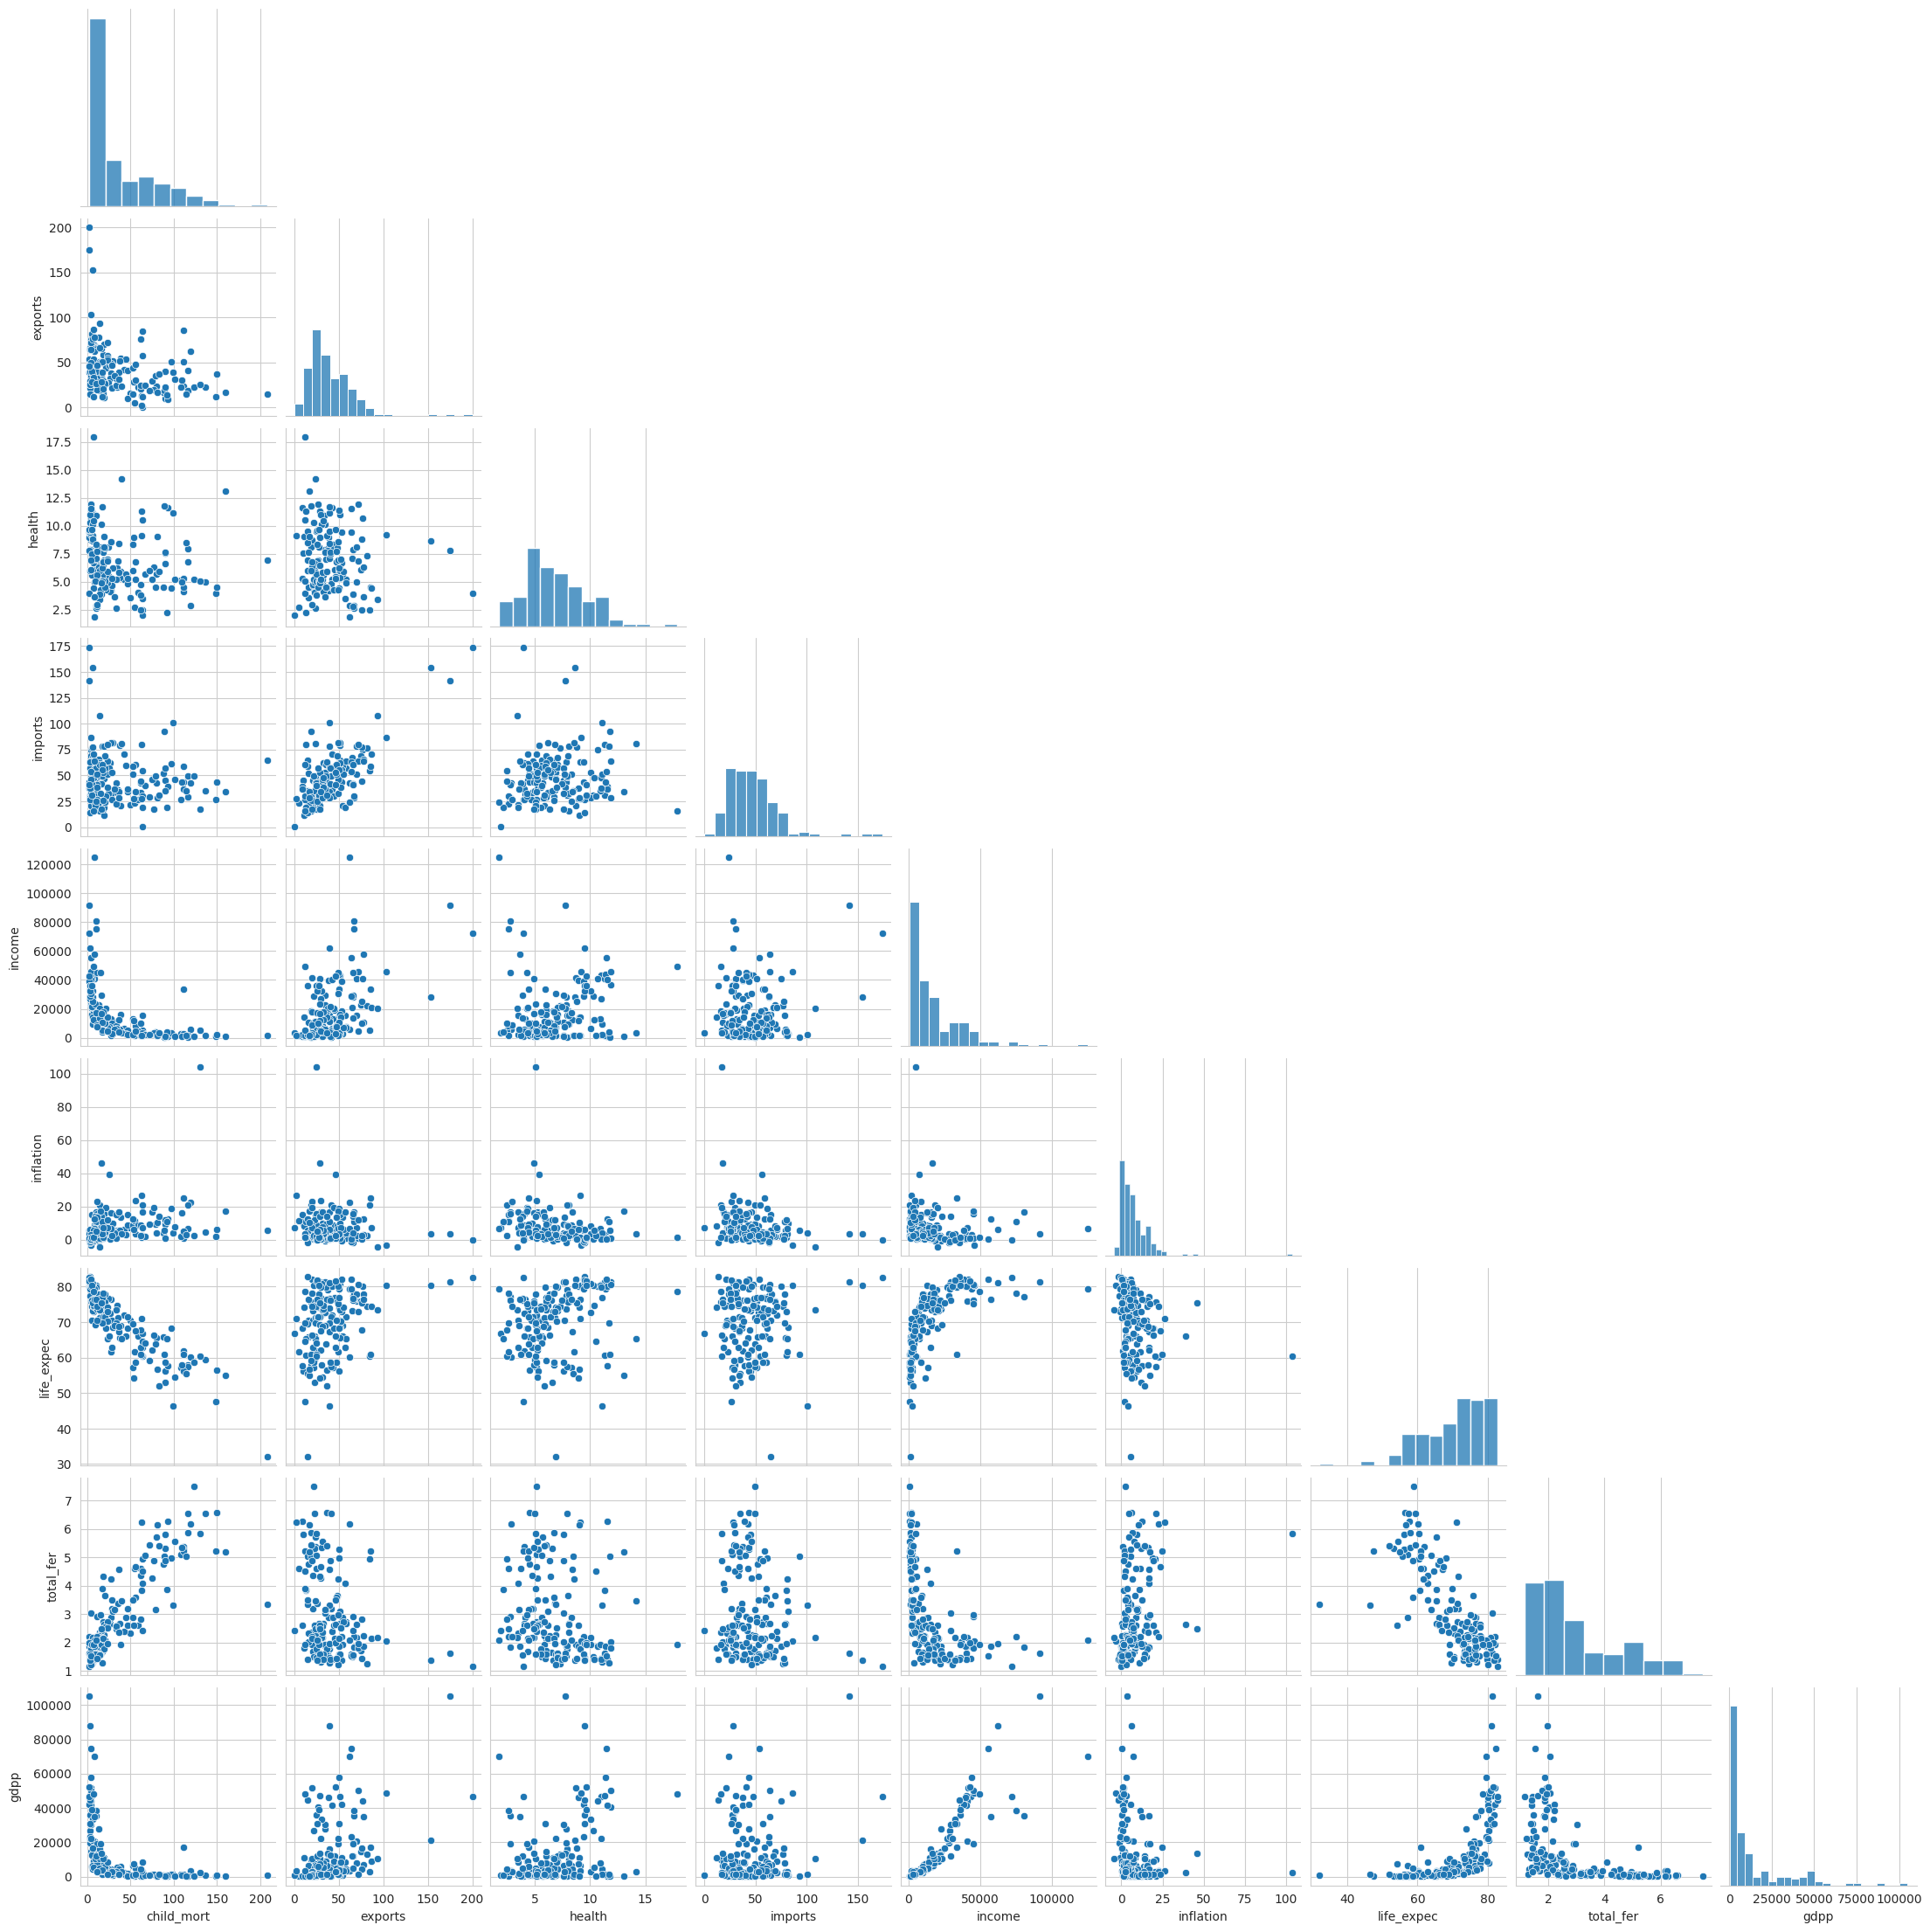

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(df_numeric, corner=True)
sns.set_style("whitegrid")
plt.figure(figsize=(15,15))
sns.pairplot(df, corner=True, diag_kind='hist')
plt.show()

## Co-related Variables

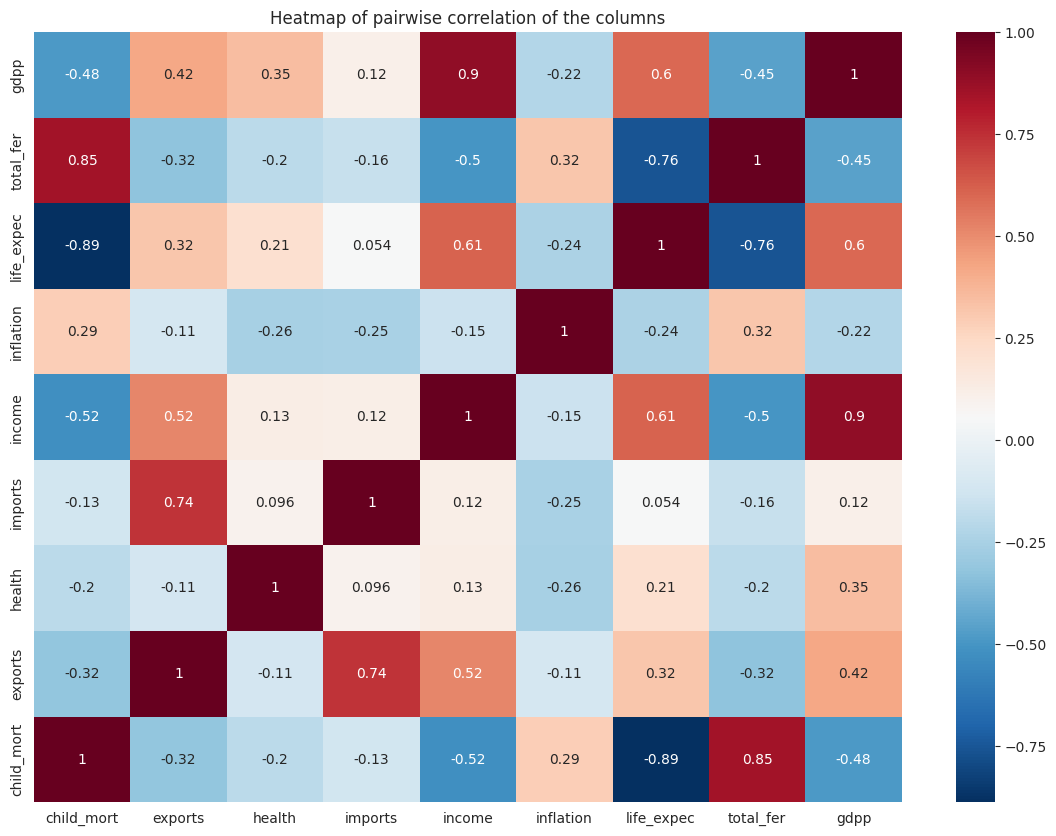

In [ ]:
np.random.seed(0)
import seaborn as sns;
import matplotlib.pyplot as plt


f, ax = plt.subplots(figsize=(14, 10))

corr = df_numeric.corr()

ax = sns.heatmap(corr, cmap = "RdBu_r",annot=True)

ax.invert_yaxis()

plt.title("Heatmap of pairwise correlation of the columns")

plt.show()

# **3. Statistical Analysis**

## Hypothesis Formulation

**Hypothesis 1**

**H₀** : There is **no significant relationship** between **child mortality** and **life expectancy**.

**H₁** :There is a **significant negative relationship** between **child mortality** and **life expectancy**.


## Statistical Tests & Justification

**Pearson Correlation Test**

In [ ]:
from scipy.stats import pearsonr

# Hypothesis 1: child_mort vs life_expec
corr1, pval1 = pearsonr(df_numeric['child_mort'], df_numeric['life_expec'])
print("Child Mortality vs Life Expectancy")
print("Correlation:", corr1)
print("p-value:", pval1)

Child Mortality vs Life Expectancy
Correlation: -0.8866760973367762
p-value: 3.7207236510334106e-57


## **p-values & Confidence**

If p-value < 0.05 → Reject H₀

If p-value ≥ 0.05 → Fail to reject H₀



**For Hypothesis 1:**

p-value < 0.05

✅ Reject H₀

✅ Accept H₁

There is a statistically significant and **strong negative relationship** between **child mortality** and **life expectancy**.

Countries with **higher** **child mortality** tend to have much **lower** **life expectancy**.

**Hypothesis 2**

**H₀** :Income has **no significant relationship** with **GDP per capita**.

**H₁** :Income has **significant positive relationship** with **GDP per capita**.


**Pearson Correlation Test**

In [ ]:
# Hypothesis 2: income vs gdpp
corr2, pval2 = pearsonr(df_numeric['income'], df_numeric['gdpp'])
print("\nIncome vs GDP per Capita")
print("Correlation:", corr2)
print("p-value:", pval2)


Income vs GDP per Capita
Correlation: 0.8955714330875313
p-value: 6.39671299749963e-60


**For Hypothesis 2:**

p-value < 0.05

✅ Reject H₀

✅ Accept H₁

There is a statistically significant and **strong positive relationship** between **income** and **GDP per capita**.

Countries with **higher** **income** levels generally have **higher** **GDP per capita**.

## Assumption Checks

### Normality

<Figure size 800x600 with 0 Axes>

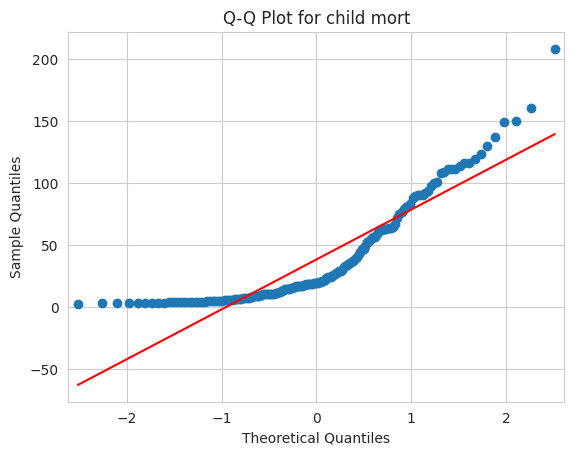

<Figure size 800x600 with 0 Axes>

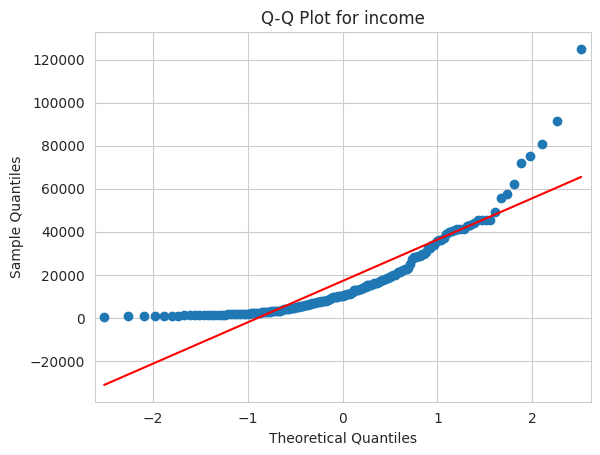

<Figure size 800x600 with 0 Axes>

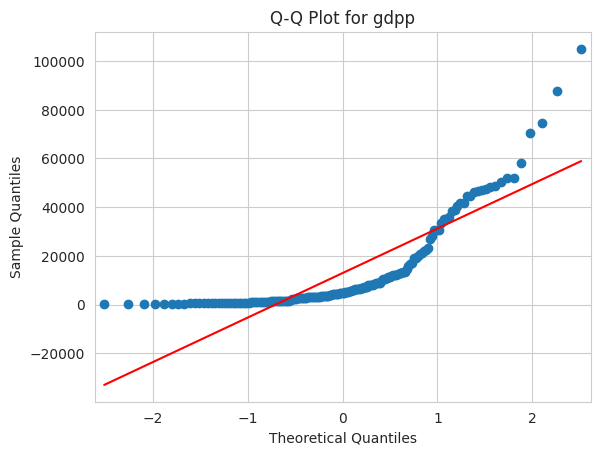

<Figure size 800x600 with 0 Axes>

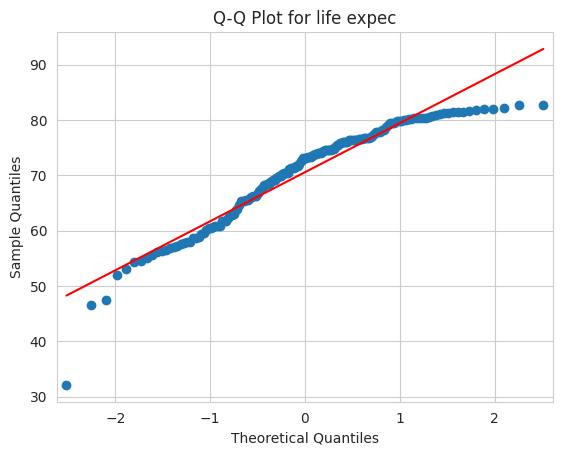

In [ ]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

columns_for_qqplot = ['child_mort', 'income', 'gdpp','life_expec']


for col in columns_for_qqplot:
    plt.figure(figsize=(8, 6))
    sm.qqplot(df_numeric[col], line='s')
    plt.title(f'Q-Q Plot for {col.replace("_", " ")}')
    plt.grid(True)
    plt.show()

# **4. Machine Learning Model Implementation**

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

## Elbow Method

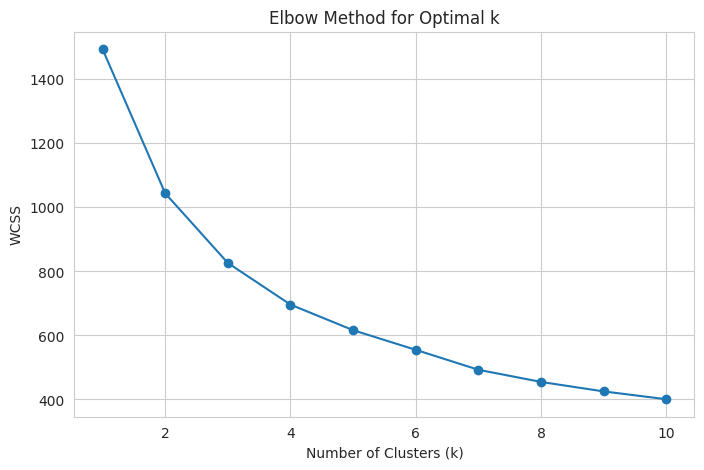

In [ ]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10,
        max_iter=300,
        random_state=42
    )
    kmeans.fit(standardized_df)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS')
plt.title('Elbow Method for Optimal k')
plt.grid(True)
plt.show()

## Silhouette Score

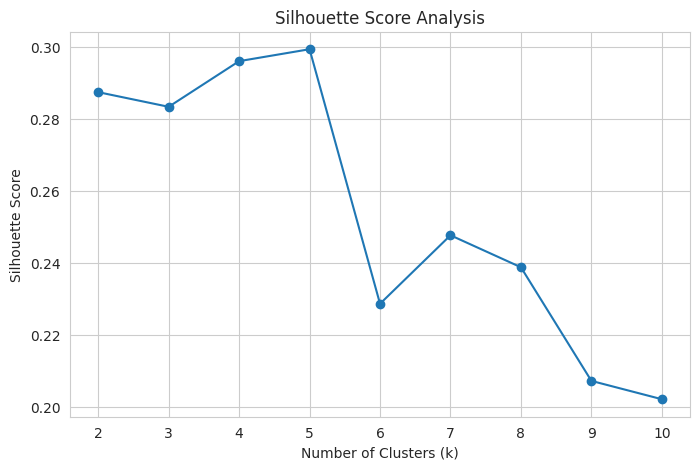

In [ ]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10,
        max_iter=300,
        random_state=42
    )
    labels = kmeans.fit_predict(standardized_df)
    score = silhouette_score(standardized_df, labels)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score Analysis')
plt.grid(True)
plt.show()

In [ ]:
!pip install kneed

## Finding the Optimal Number of Clusters using KneeLocator

In [ ]:
from kneed import KneeLocator

kl=KneeLocator(range(1,11),wcss,curve='convex',direction='decreasing')
print(kl.elbow)

4


## **K Means**

In [ ]:
# Optimal k chosen based on Elbow & Silhouette

kmeans_final = KMeans(
    n_clusters=4,
    init='k-means++',
    n_init=10,
    max_iter=300,
    random_state=42
)

kmeans_labels = kmeans_final.fit_predict(standardized_df)
# Attach Cluster Labels
df_kmeans = df.copy()
df_kmeans['cluster'] = kmeans_labels

In [ ]:
# Cluster Summary
df_kmeans.groupby('cluster').mean(numeric_only=True)
# cluster_summary = df_kmeans.groupby('cluster').mean(numeric_only=True)
# print(cluster_summary)

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
cluster,,,,,,,,,
0,5.181250,46.118750,9.088437,40.584375,44021.875000,2.513844,80.081250,1.788437,42118.750000
1,92.961702,29.151277,6.388511,42.323404,3942.404255,12.019681,59.187234,5.008085,1922.382979
2,21.690588,41.073988,6.197059,47.914893,12671.411765,7.609341,72.871765,2.300706,6519.552941
3,4.133333,176.000000,6.793333,156.666667,64033.333333,2.468000,81.433333,1.380000,57566.666667


In [ ]:
kmeans_mapping = {
    1: "High-Need",
    2: "Medium-Need",
    0: "Low-Need",
    3: "Very Low-Need"
}

df_kmeans['Need_Level'] = df_kmeans['cluster'].map(kmeans_mapping)

# **Hierarchical Clustering**

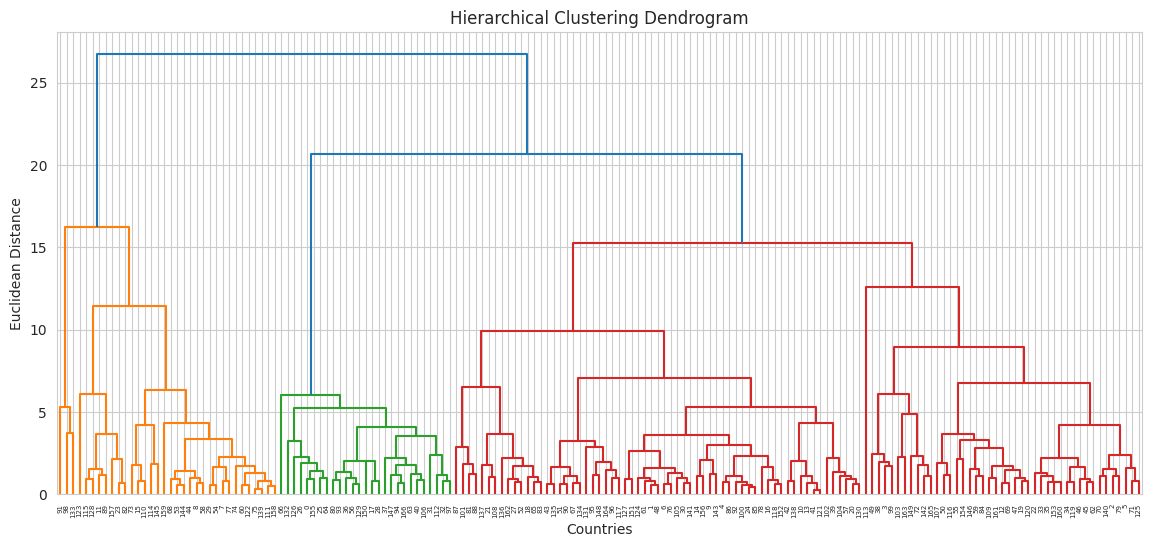

In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

# Linkage matrix
linked = linkage(standardized_df, method='ward')

plt.figure(figsize=(14, 6))
dendrogram(linked)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Countries')
plt.ylabel('Euclidean Distance')
plt.show()

In [ ]:
from scipy.cluster.hierarchy import fcluster

hc_labels = fcluster(linked, t=4, criterion='maxclust')

df_hc = df.copy()
df_hc['hc_cluster'] = hc_labels

In [ ]:
df_hc.groupby('hc_cluster').mean(numeric_only=True)

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
hc_cluster,,,,,,,,,
1,4.133333,176.000000,6.793333,156.666667,64033.333333,2.468000,81.433333,1.380000,57566.666667
2,6.138710,47.138710,8.666452,38.474194,45996.774194,4.274935,79.841935,1.937742,41777.419355
3,105.070370,23.589630,6.507037,39.662963,1589.740741,7.142778,57.248148,5.433704,667.888889
4,31.617925,39.990368,6.353679,48.085527,11341.886792,9.120604,70.921698,2.654623,6407.367925


In [ ]:
hc_mapping = {
    3: "High-Need",
    4: "Medium-Need",
    2: "Low-Need",
    1: "Very Low-Need"
}

df_hc['Need_Level'] = df_hc['hc_cluster'].map(hc_mapping)

# **5. Evaluation & Comparison of Results**

## Performance Metrics

## K-Means Evaluation

In [ ]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Calculate Silhouette Score
silhouette = silhouette_score(standardized_df, kmeans_labels)
print(f"Silhouette Score: {silhouette:.3f}")

# Calculate Davies-Bouldin Index
davies_bouldin = davies_bouldin_score(standardized_df, kmeans_labels)
print(f"Davies-Bouldin Index: {davies_bouldin:.3f}")

# Calculate Calinski-Harabasz Index
calinski_harabasz = calinski_harabasz_score(standardized_df, kmeans_labels)
print(f"Calinski-Harabasz Index: {calinski_harabasz:.3f}")

Silhouette Score: 0.296
Davies-Bouldin Index: 1.053
Calinski-Harabasz Index: 62.241


## Hierarchical Clustering Evaluation

In [ ]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Calculate Silhouette Score for Hierarchical Clustering
silhouette_hc = silhouette_score(standardized_df, hc_labels)
print(f"Hierarchical Clustering Silhouette Score: {silhouette_hc:.3f}")

# Calculate Davies-Bouldin Index for Hierarchical Clustering
davies_bouldin_hc = davies_bouldin_score(standardized_df, hc_labels)
print(f"Hierarchical Clustering Davies-Bouldin Index: {davies_bouldin_hc:.3f}")

# Calculate Calinski-Harabasz Index for Hierarchical Clustering
calinski_harabasz_hc = calinski_harabasz_score(standardized_df, hc_labels)
print(f"Hierarchical Clustering Calinski-Harabasz Index: {calinski_harabasz_hc:.3f}")

Hierarchical Clustering Silhouette Score: 0.248
Hierarchical Clustering Davies-Bouldin Index: 1.080
Hierarchical Clustering Calinski-Harabasz Index: 48.263


## Comparison of K-Means and Hierarchical Clustering Models

| Metric                | K-Means (4 Clusters) | Hierarchical Clustering (4 Clusters) |
| :-------------------- | :------------------- | :----------------------------------- |
| **Silhouette Score**  | 0.296                | 0.248                                |
| **Davies-Bouldin Index** | 1.053                | 1.080                                |
| **Calinski-Harabasz Index** | 62.241               | 48.263                               |


To identify **High-Need countries**, we compared **K-Means** and **Hierarchical Clustering** using three internal evaluation metrics.

### Silhouette Score
- **K-Means:** 0.296  
- **Hierarchical Clustering:** 0.248  

A higher Silhouette Score indicates better clustering quality.  
K-Means has a higher score, which means its clusters are more compact and better separated.

### Davies-Bouldin Index
- **K-Means:** 1.053  
- **Hierarchical Clustering:** 1.080  

A lower Davies-Bouldin Index is better.  
K-Means has a lower value, indicating better separation between clusters and higher internal consistency.

### Calinski-Harabasz Index
- **K-Means:** 62.241  
- **Hierarchical Clustering:** 48.263  

A higher Calinski-Harabasz Index means stronger clustering structure.  
K-Means has a much higher score, showing well-separated and dense clusters.

## Conclusion
Based on all three evaluation metrics, **K-Means clustering with 4 clusters performs better than Hierarchical Clustering** for this dataset.

K-Means produces clusters that are:
- More compact  
- Better separated  
- More clearly structured  

Therefore, **K-Means is the more suitable method for identifying High-Need countries** in this study.


## `Child Mortality` vs. `GDP per Capita`

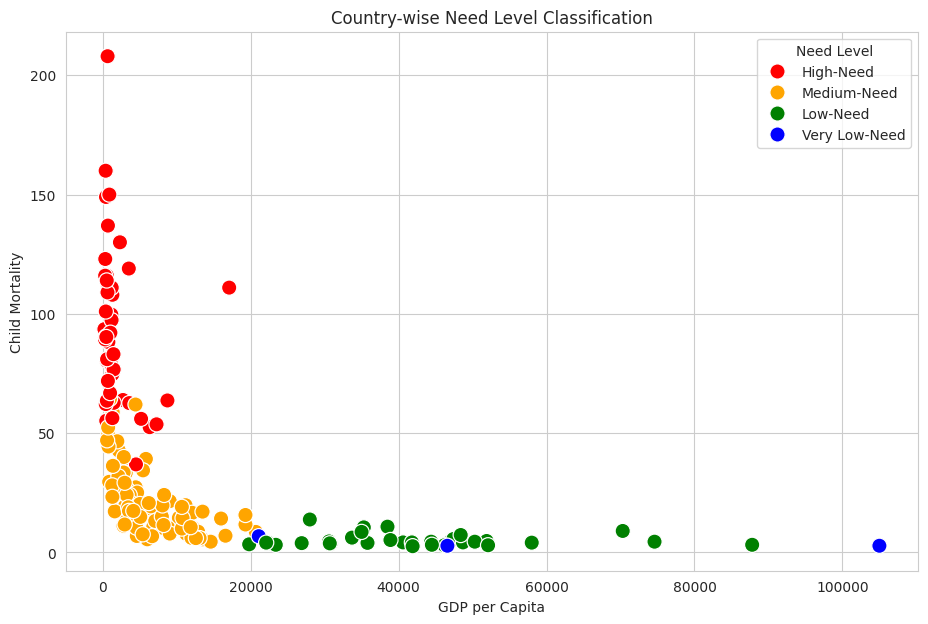

In [ ]:
plt.figure(figsize=(11,7))

sns.scatterplot(
    data=df_kmeans,
    x='gdpp',
    y='child_mort',
    hue='Need_Level',
    palette={
        "High-Need": "red",
        "Medium-Need": "orange",
        "Low-Need": "green",
        "Very Low-Need": "blue"
    },
    s=120
)

plt.xlabel("GDP per Capita")
plt.ylabel("Child Mortality")
plt.title("Country-wise Need Level Classification")
plt.grid(True)
plt.legend(title="Need Level")
plt.show()

## `Life Expectancy` vs. `Income`

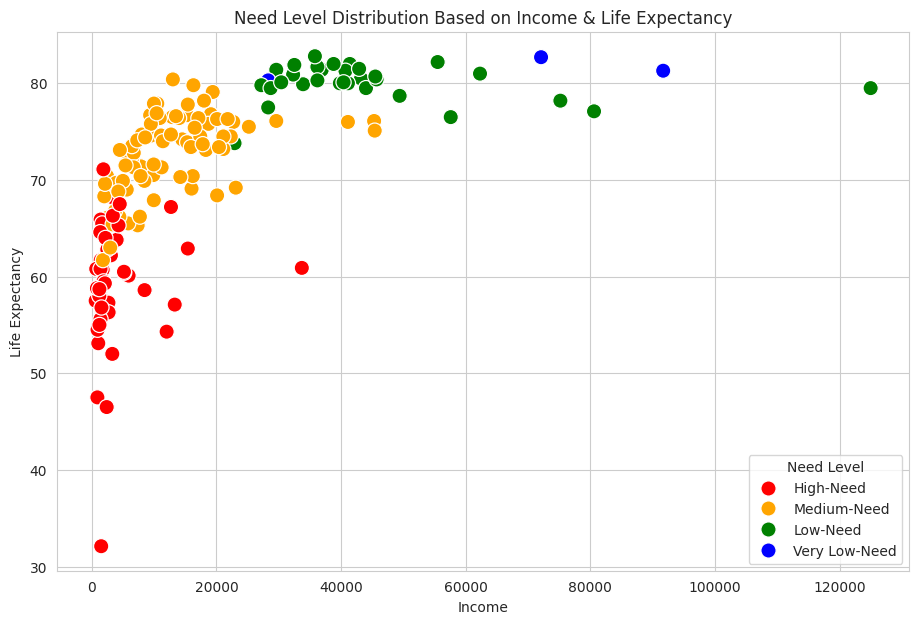

In [ ]:
plt.figure(figsize=(11,7))

sns.scatterplot(
    data=df_kmeans,
    x='income',
    y='life_expec',
    hue='Need_Level',
    palette={
        "High-Need": "red",
        "Medium-Need": "orange",
        "Low-Need": "green",
        "Very Low-Need": "blue"
    },
    s=120
)

plt.xlabel("Income")
plt.ylabel("Life Expectancy")
plt.title("Need Level Distribution Based on Income & Life Expectancy")
plt.grid(True)
plt.legend(title="Need Level")
plt.show()


## `Total Fertility` vs. `Health Spending`

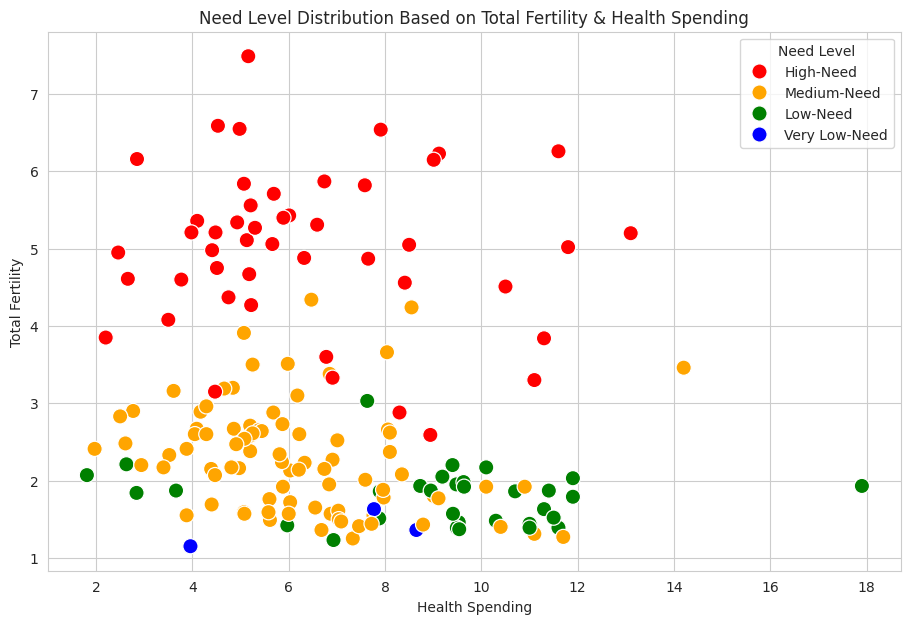

In [ ]:
plt.figure(figsize=(11,7))

sns.scatterplot(
    data=df_kmeans,
    x='health',
    y='total_fer',
    hue='Need_Level',
    palette={
        "High-Need": "red",
        "Medium-Need": "orange",
        "Low-Need": "green",
        "Very Low-Need": "blue"
    },
    s=120
)

plt.xlabel("Health Spending")
plt.ylabel("Total Fertility")
plt.title("Need Level Distribution Based on Total Fertility & Health Spending")
plt.grid(True)
plt.legend(title="Need Level")
plt.show()

## `Inflation` vs. `GDP per Capita`

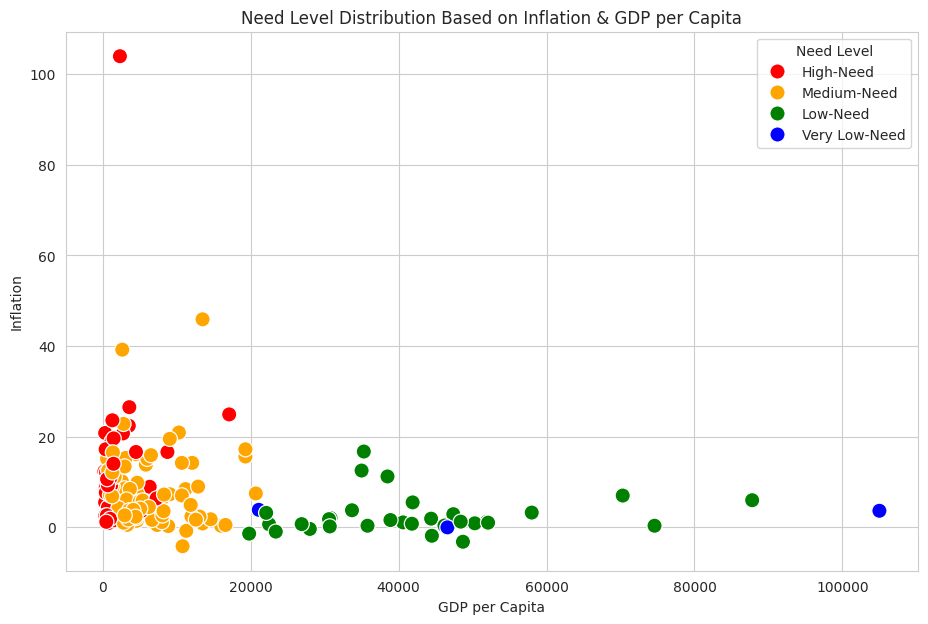

In [ ]:
plt.figure(figsize=(11,7))

sns.scatterplot(
    data=df_kmeans,
    x='gdpp',
    y='inflation',
    hue='Need_Level',
    palette={
        "High-Need": "red",
        "Medium-Need": "orange",
        "Low-Need": "green",
        "Very Low-Need": "blue"
    },
    s=120
)

plt.xlabel("GDP per Capita")
plt.ylabel("Inflation")
plt.title("Need Level Distribution Based on Inflation & GDP per Capita")
plt.grid(True)
plt.legend(title="Need Level")
plt.show()

## Top 20 High-Need Countries by Inflation

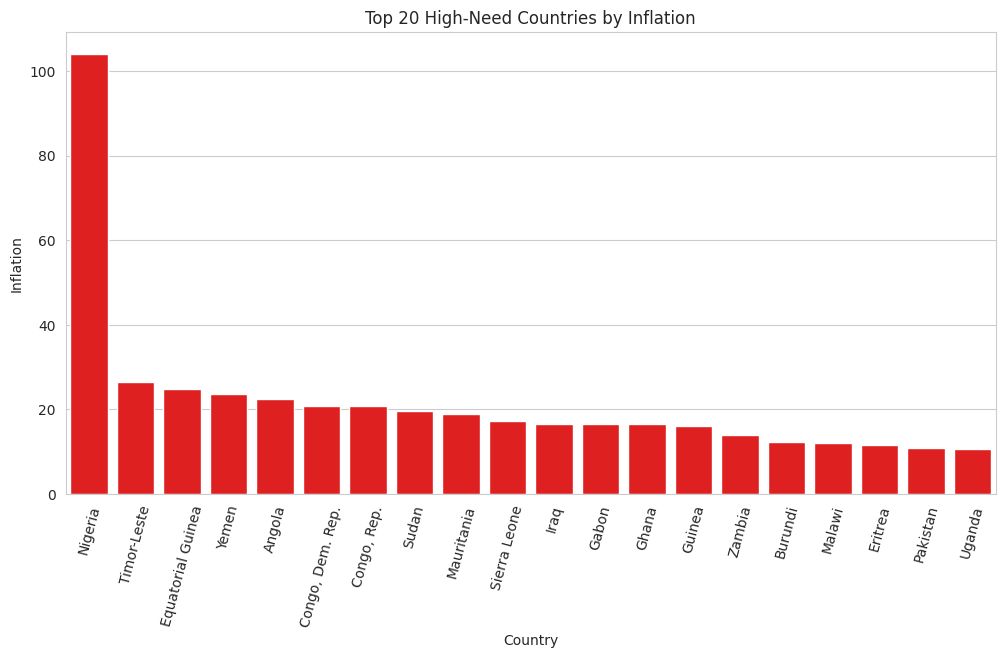

In [ ]:
high_need = df_kmeans[df_kmeans['Need_Level'] == 'High-Need'] \
    .sort_values('inflation',ascending=False) \
    .head(20)

plt.figure(figsize=(12,6))
sns.barplot(
    data=high_need,
    x='country',
    y='inflation',
    color='red'
)

plt.xticks(rotation=75)
plt.xlabel("Country")
plt.ylabel("Inflation")
plt.title("Top 20 High-Need Countries by Inflation")
plt.show()

## Top 20 High-Need Countries by Child Mortality

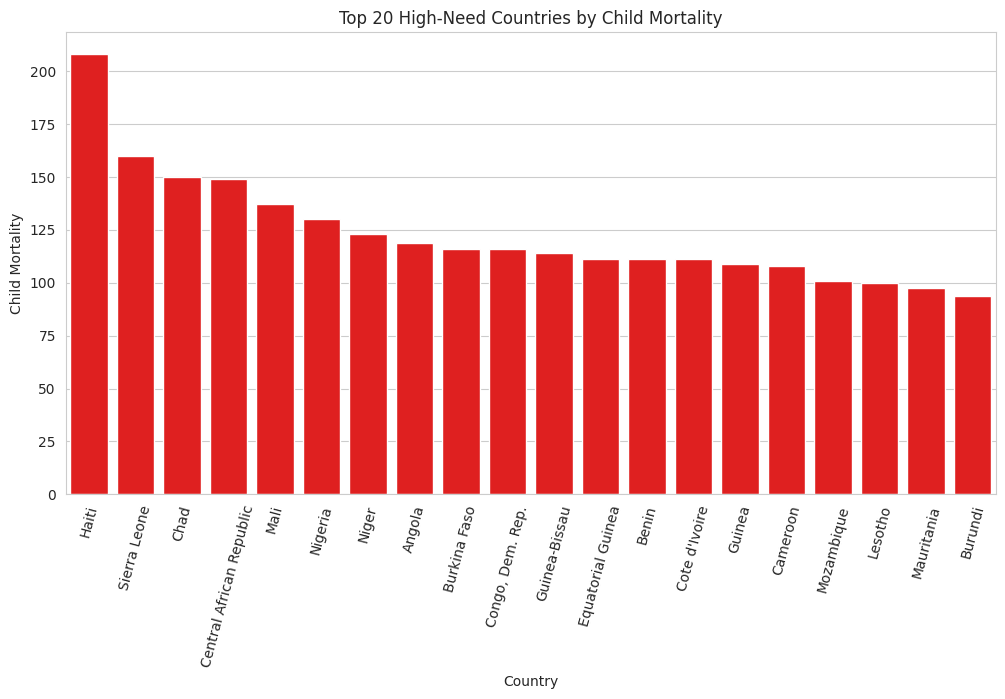

In [ ]:
high_need = df_kmeans[df_kmeans['Need_Level'] == 'High-Need'] \
    .sort_values('child_mort',ascending=False) \
    .head(20)

plt.figure(figsize=(12,6))
sns.barplot(
    data=high_need,
    x='country',
    y='child_mort',
    color='red'
)

plt.xticks(rotation=75)
plt.xlabel("Country")
plt.ylabel("Child Mortality")
plt.title("Top 20 High-Need Countries by Child Mortality")
plt.show()

## Top 20 High-Need Countries by Health Spending

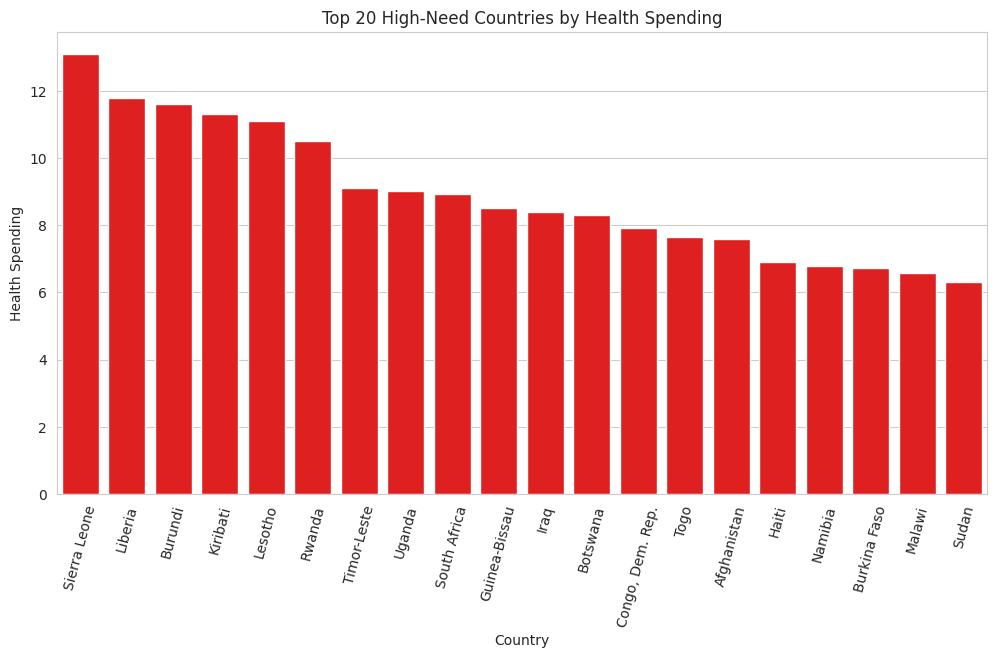

In [ ]:
high_need = df_kmeans[df_kmeans['Need_Level'] == 'High-Need'] \
    .sort_values('health',ascending=False) \
    .head(20)

plt.figure(figsize=(12,6))
sns.barplot(
    data=high_need,
    x='country',
    y='health',
    color='red'
)

plt.xticks(rotation=75)
plt.xlabel("Country")
plt.ylabel("Health Spending")
plt.title("Top 20 High-Need Countries by Health Spending")
plt.show()